# QBUS6860_Individual Assignment - SID:520380808

# Summary of this file

This `ipynb` file includes all of my code that I used to analysis & export figures. I worte it from how I cleaned the given csv file, how I generate the figure I want to talk in the video.

## Part 1: Data Cleaning

### Load csv file

In [31]:
import pandas as pd 
import geopandas as gpd
import os
import zipfile
import sys
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
import warnings
from matplotlib import MatplotlibDeprecationWarning
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import json
import plotly.graph_objects as go

education_df = pd.read_csv('data/Education-services-with-station-access_loc.csv',low_memory=False)

education_df.head()

,ServiceApprovalNumber,Provider Approval Number,ServiceName,ProviderLegalName,ServiceType,ServiceAddress,Suburb,State,Postcode,Phone,...,Holiday Care Saturday End Time,Holiday Care Sunday Start Time,Holiday Care Sunday End Time,Temporarily Closed,FullAddress,geometry,ClosestTrainStation,ClosestBusStation,DistanceToTrainStation_km,DistanceToBusStation_km
0,SE-00000002,PR-00000898,Community Kids Waterford Early Education Centre,G8 Education Limited,Centre-Based Care,8-10 Allora St,WATERFORD WEST,QLD,4133.0,0732009852,...,NaN,NaN,NaN,No,"8-10 Allora St, WATERFORD WEST, QLD, 4133","c(153.133902919075, -27.690513207433)",Loganlea,Clarks Logan City Bus Service - Bus Depot,2.240936,2.740061
1,SE-00000003,PR-40029099,KIDVENTURE EARLY LEARNING EAGLEBY,Table Mountain Trading Pty Ltd As The Trustee ...,Centre-Based Care,82 Fryar Road,EAGLEBY,QLD,4207.0,0738073222,...,NaN,NaN,NaN,No,"82 Fryar Road, EAGLEBY, QLD, 4207","c(153.211787647201, -27.707467576353)",Beenleigh,Loganholme station,1.321988,6.463300
2,SE-00000004,PR-00000898,Community Kids - Broadbeach Waters,G8 Education Limited,Centre-Based Care,4 Fremar Street,BROADBEACH WATERS,QLD,4217.0,0755920306,...,NaN,NaN,NaN,No,"4 Fremar Street, BROADBEACH WATERS, QLD, 4217","c(153.410339594544, -28.024767831911)",Broadbeach North,Greyhound Bus Terminal Surfers Paradise,1.934140,2.921968
3,SE-00000005,PR-40002184,Little Scholars School of Early Learning Burle...,The Scholars Group Pty Ltd,Centre-Based Care,143 Christine Ave,BURLEIGH WATERS,QLD,4220.0,0755353288,...,NaN,NaN,NaN,No,"143 Christine Ave, BURLEIGH WATERS, QLD, 4220","c(153.431380518447, -28.082157591396)",Varsity Lakes,Greyhound Bus Terminal Surfers Paradise,3.570195,8.819896
4,SE-00000006,PR-40029104,Small World Child Care Centre,A. & K. Massouras Pty. Ltd. ATF The A Massoura...,Centre-Based Care,113-115 Pappas Way,CARRARA,QLD,4211.0,07 5594 1844,...,NaN,NaN,NaN,No,"113-115 Pappas Way, CARRARA, QLD, 4211","c(153.351670127991, -28.005580607804)",Nerang,Greyhound Bus Terminal Surfers Paradise,1.287302,7.408396


### Start cleaning

In [32]:
# As can see from above, column names are not very descriptive, so convert it to snnake case for better readability
education_df.columns = (
    pd.Index(education_df.columns)
    .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)
education_df.head()

,service_approval_number,provider_approval_number,service_name,provider_legal_name,service_type,service_address,suburb,state,postcode,phone,...,holiday_care_saturday_end_time,holiday_care_sunday_start_time,holiday_care_sunday_end_time,temporarily_closed,full_address,geometry,closest_train_station,closest_bus_station,distance_to_train_station_km,distance_to_bus_station_km
0,SE-00000002,PR-00000898,Community Kids Waterford Early Education Centre,G8 Education Limited,Centre-Based Care,8-10 Allora St,WATERFORD WEST,QLD,4133.0,0732009852,...,NaN,NaN,NaN,No,"8-10 Allora St, WATERFORD WEST, QLD, 4133","c(153.133902919075, -27.690513207433)",Loganlea,Clarks Logan City Bus Service - Bus Depot,2.240936,2.740061
1,SE-00000003,PR-40029099,KIDVENTURE EARLY LEARNING EAGLEBY,Table Mountain Trading Pty Ltd As The Trustee ...,Centre-Based Care,82 Fryar Road,EAGLEBY,QLD,4207.0,0738073222,...,NaN,NaN,NaN,No,"82 Fryar Road, EAGLEBY, QLD, 4207","c(153.211787647201, -27.707467576353)",Beenleigh,Loganholme station,1.321988,6.463300
2,SE-00000004,PR-00000898,Community Kids - Broadbeach Waters,G8 Education Limited,Centre-Based Care,4 Fremar Street,BROADBEACH WATERS,QLD,4217.0,0755920306,...,NaN,NaN,NaN,No,"4 Fremar Street, BROADBEACH WATERS, QLD, 4217","c(153.410339594544, -28.024767831911)",Broadbeach North,Greyhound Bus Terminal Surfers Paradise,1.934140,2.921968
3,SE-00000005,PR-40002184,Little Scholars School of Early Learning Burle...,The Scholars Group Pty Ltd,Centre-Based Care,143 Christine Ave,BURLEIGH WATERS,QLD,4220.0,0755353288,...,NaN,NaN,NaN,No,"143 Christine Ave, BURLEIGH WATERS, QLD, 4220","c(153.431380518447, -28.082157591396)",Varsity Lakes,Greyhound Bus Terminal Surfers Paradise,3.570195,8.819896
4,SE-00000006,PR-40029104,Small World Child Care Centre,A. & K. Massouras Pty. Ltd. ATF The A Massoura...,Centre-Based Care,113-115 Pappas Way,CARRARA,QLD,4211.0,07 5594 1844,...,NaN,NaN,NaN,No,"113-115 Pappas Way, CARRARA, QLD, 4211","c(153.351670127991, -28.005580607804)",Nerang,Greyhound Bus Terminal Surfers Paradise,1.287302,7.408396


In [33]:
# change geometry column to another name to avoid confusion with geospatial dataframes
education_df = education_df.rename(columns={"geometry": "geometry_raw"})

# strip leading and trailing whitespace from text columns and convert to string type
text_cols = education_df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    education_df[col] = education_df[col].astype("string").str.strip()

education_df = education_df.replace({"": pd.NA, "NA": pd.NA, "N/A": pd.NA, "na": pd.NA, "n/a": pd.NA})

# convert selctive columns, and remove space before and after the numbers
string_cols = [
    "service_approval_number",
    "provider_approval_number",
    "service_name",
    "provider_legal_name",
    "service_type",
    "service_address",
    "suburb",
    "state",
    "phone",
    "fax",
    "conditions_on_approval",
    "overall_rating",
    "ratings_issued",
    "previous_overall_rating",
    "previous_ratings_issued",
    "closest_train_station",
    "closest_bus_station",
    "full_address",
    "geometry_raw",
]

for col in string_cols:
    if col in education_df.columns:
        education_df[col] = education_df[col].astype("string")

for col in ["phone", "fax"]:
    if col in education_df.columns:
        education_df[col] = education_df[col].str.replace(r"\s+", "", regex=True)

# convert numeric columns to appropriate types
education_df["postcode"] = pd.to_numeric(education_df["postcode"], errors="coerce").astype("Int64").astype("string").str.zfill(4)
education_df["number_of_approved_places"] = pd.to_numeric(education_df["number_of_approved_places"], errors="coerce")
education_df["distance_to_train_station_km"] = pd.to_numeric(education_df["distance_to_train_station_km"], errors="coerce")
education_df["distance_to_bus_station_km"] = pd.to_numeric(education_df["distance_to_bus_station_km"], errors="coerce")

# Convert Yes/No fields to nullable booleans
yes_no_cols = []
for col in education_df.columns:
    non_missing_values = set(education_df[col].dropna().astype(str).unique())
    if len(non_missing_values) > 0 and non_missing_values.issubset({"Yes", "No"}):
        yes_no_cols.append(col)

for col in yes_no_cols:
    education_df[col] = education_df[col].map({"Yes": True, "No": False}).astype("boolean")

# Parse date columns, and standardise all time columns to HH:MM:SS
day_month_year_cols = [ "service_approval_granted_date", "last_service_approval_transfer_date"]
for col in day_month_year_cols:
    if col in education_df.columns:
        education_df[col] = pd.to_datetime(education_df[col], format="%d/%m/%Y", errors="coerce")

month_year_cols = ["ratings_issued", "previous_ratings_issued"]
for col in month_year_cols:
    if col in education_df.columns:
        education_df[col] = pd.to_datetime(education_df[col], format="%b %Y", errors="coerce")

time_cols = [col for col in education_df.columns if "time" in col]

for col in time_cols:
    education_df[col] = education_df[col].astype("string").str.strip()
    education_df[col] = education_df[col].str.replace(r"\.(?=\d)", ":", regex=True)
    education_df[col] = education_df[col].str.replace(r"\.(?=:)", "", regex=True)
    education_df[col] = education_df[col].str.replace(r"^(\d{1,2})(\d{2})$", r"\1:\2", regex=True)
    education_df[col] = pd.to_datetime(education_df[col], format="mixed", errors="coerce").dt.strftime("%H:%M:%S")
    education_df[col] = education_df[col].astype("string")

# Extract longitude / latitude from geometry string
education_df["longitude"] = pd.to_numeric(
    education_df["geometry_raw"].str.extract(r"c\(\s*([-0-9\.]+)")[0],
    errors="coerce",
)
education_df["latitude"] = pd.to_numeric(
    education_df["geometry_raw"].str.extract(r"c\(\s*[-0-9\.]+\s*,\s*([-0-9\.]+)\s*\)")[0],
    errors="coerce",
)

education_df.head()

,service_approval_number,provider_approval_number,service_name,provider_legal_name,service_type,service_address,suburb,state,postcode,phone,...,holiday_care_sunday_end_time,temporarily_closed,full_address,geometry_raw,closest_train_station,closest_bus_station,distance_to_train_station_km,distance_to_bus_station_km,longitude,latitude
0,SE-00000002,PR-00000898,Community Kids Waterford Early Education Centre,G8 Education Limited,Centre-Based Care,8-10 Allora St,WATERFORD WEST,QLD,4133,0732009852,...,<NA>,False,"8-10 Allora St, WATERFORD WEST, QLD, 4133","c(153.133902919075, -27.690513207433)",Loganlea,Clarks Logan City Bus Service - Bus Depot,2.240936,2.740061,153.133903,-27.690513
1,SE-00000003,PR-40029099,KIDVENTURE EARLY LEARNING EAGLEBY,Table Mountain Trading Pty Ltd As The Trustee ...,Centre-Based Care,82 Fryar Road,EAGLEBY,QLD,4207,0738073222,...,<NA>,False,"82 Fryar Road, EAGLEBY, QLD, 4207","c(153.211787647201, -27.707467576353)",Beenleigh,Loganholme station,1.321988,6.463300,153.211788,-27.707468
2,SE-00000004,PR-00000898,Community Kids - Broadbeach Waters,G8 Education Limited,Centre-Based Care,4 Fremar Street,BROADBEACH WATERS,QLD,4217,0755920306,...,<NA>,False,"4 Fremar Street, BROADBEACH WATERS, QLD, 4217","c(153.410339594544, -28.024767831911)",Broadbeach North,Greyhound Bus Terminal Surfers Paradise,1.934140,2.921968,153.41034,-28.024768
3,SE-00000005,PR-40002184,Little Scholars School of Early Learning Burle...,The Scholars Group Pty Ltd,Centre-Based Care,143 Christine Ave,BURLEIGH WATERS,QLD,4220,0755353288,...,<NA>,False,"143 Christine Ave, BURLEIGH WATERS, QLD, 4220","c(153.431380518447, -28.082157591396)",Varsity Lakes,Greyhound Bus Terminal Surfers Paradise,3.570195,8.819896,153.431381,-28.082158
4,SE-00000006,PR-40029104,Small World Child Care Centre,A. & K. Massouras Pty. Ltd. ATF The A Massoura...,Centre-Based Care,113-115 Pappas Way,CARRARA,QLD,4211,0755941844,...,<NA>,False,"113-115 Pappas Way, CARRARA, QLD, 4211","c(153.351670127991, -28.005580607804)",Nerang,Greyhound Bus Terminal Surfers Paradise,1.287302,7.408396,153.35167,-28.005581


I have now finished some basic data clean. Now, I think I need to check if all geometry are valid. Based on the assignment details, geometry data may have error.

## Check the potential error from geometry coordinates

I will using the following codes to check the potential error from geometry coordinates. For more specifc:
- Detect the frequently occurring coordinates
- Verify whether the column addresses of the coordinates at this time are missing 
- Verify whether the coordinates exceed the reasonable range of Australia

And if the coordinates satisfied above conditions, it will be marked as flag as error geometry coordinates.

In [34]:
education_df["full_address_missing_like"] = ( education_df["full_address"].isna() | education_df["full_address"].eq("NA, NA, NA, NA"))

core_address_cols = ["service_address", "suburb", "state", "postcode"]

for col in core_address_cols:
    education_df[f"{col}_missing"] = education_df[col].isna()

geometry_diagnostic = (
    education_df.dropna(subset=["geometry_raw"])
    .groupby("geometry_raw", dropna=False)
    .agg(
        n_records=("geometry_raw", "size"),
        longitude=("longitude", "first"),
        latitude=("latitude", "first"),
        n_unique_full_address=("full_address", "nunique"),
        full_address_missing_count=("full_address_missing_like", "sum"),
        service_address_missing_count=("service_address_missing", "sum"),
        suburb_missing_count=("suburb_missing", "sum"),
        state_missing_count=("state_missing", "sum"),
        postcode_missing_count=("postcode_missing", "sum"),
    )
    .reset_index()
)

# check if all records with the same geometry_raw have missing full_address
geometry_diagnostic["all_full_address_missing"] = (
    geometry_diagnostic["full_address_missing_count"] == geometry_diagnostic["n_records"]
)

geometry_diagnostic["all_core_address_missing"] = (
    (geometry_diagnostic["service_address_missing_count"] == geometry_diagnostic["n_records"])
    & (geometry_diagnostic["suburb_missing_count"] == geometry_diagnostic["n_records"])
    & (geometry_diagnostic["state_missing_count"] == geometry_diagnostic["n_records"])
    & (geometry_diagnostic["postcode_missing_count"] == geometry_diagnostic["n_records"])
)

# check if the coordinates are outside reasonable bounds for Australia
geometry_diagnostic["outside_aus_bounds"] = (
    geometry_diagnostic["longitude"].isna()
    | geometry_diagnostic["latitude"].isna()
    | (geometry_diagnostic["longitude"] < 105)
    | (geometry_diagnostic["longitude"] > 160)
    | (geometry_diagnostic["latitude"] < -45)
    | (geometry_diagnostic["latitude"] > -8)
)

# find suspicious geometry values that are repeated multiple times and have missing addresses or outside Australia bounds
suspicious_geometry_values = geometry_diagnostic.loc[
    (geometry_diagnostic["n_records"] >= 3)
    & (
        geometry_diagnostic["all_full_address_missing"]
        | geometry_diagnostic["all_core_address_missing"]
        | geometry_diagnostic["outside_aus_bounds"]
    ),
    "geometry_raw",
].tolist()

print("Suspicious repeated geometry values:")
print(
    geometry_diagnostic.loc[
        geometry_diagnostic["geometry_raw"].isin(suspicious_geometry_values),
        [
            "geometry_raw",
            "n_records",
            "n_unique_full_address",
            "all_full_address_missing",
            "all_core_address_missing",
            "outside_aus_bounds",
        ],
    ].sort_values("n_records", ascending=False)
)

Suspicious repeated geometry values:
                geometry_raw  n_records  n_unique_full_address  \
16885  c(97.48747, 23.14958)         10                      1   

       all_full_address_missing  all_core_address_missing  outside_aus_bounds  
16885                      True                      True                True  


Based on above output, we can know that geometry_raw: c(97.48747, 23.14958) appears 10 times & full address missing or core address missing or outside australia bounds. So I will flag them as invalid geometry location.

In [35]:
# Flag invalid / placeholder spatial rows
education_df["placeholder_location_flag"] = education_df["geometry_raw"].isin(suspicious_geometry_values)

education_df["out_of_range_flag"] = (
    education_df["longitude"].isna()
    | education_df["latitude"].isna()
    | (education_df["longitude"] < 105)
    | (education_df["longitude"] > 160)
    | (education_df["latitude"] < -45)
    | (education_df["latitude"] > -8)
)

education_df["invalid_spatial_flag"] = (
    education_df["placeholder_location_flag"]
    | education_df["out_of_range_flag"]
)

# they can not be used for spatial analysis
education_df.loc[
    education_df["invalid_spatial_flag"],
    [
        "longitude",
        "latitude",
        "closest_train_station",
        "closest_bus_station",
        "distance_to_train_station_km",
        "distance_to_bus_station_km",
    ],
] = pd.NA

education_df["valid_spatial_record"] = education_df[["longitude", "latitude"]].notna().all(axis=1)

# Create GeoDataFrame from valid coordinates
services_gdf = gpd.GeoDataFrame(
    education_df.copy(),
    geometry=gpd.points_from_xy(education_df["longitude"], education_df["latitude"]),
    crs="EPSG:4326",
)
services_gdf.loc[~services_gdf["valid_spatial_record"], "geometry"] = None

## Urban/rural classification

Now, based on assignment description, and I want to analysis the difference between urban & rural, so I will choose SOS file from ABS and use GeoPandas as spatial join to match each service’s coordinates to the boundary polygon it falls within.

The way how I download SOS file from ABS:
- I choose the selected zip file from part **Significant Urban Areas, Urban Centres and Localities, Section of State and Section of State Range** with specific topic: **- Section of State - 2021 - Shapefile**
- Link about this file from ABS website: https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs-edition-3/jul2021-jun2026/access-and-downloads/digital-boundary-files/SOS_2021_AUST_GDA2020_SHP.zip

I have downloaded it and place it into data folder of this project. Therefore when using it, I will read it from the local project path.

In [36]:
# Read SOS shapefile directly from local
sos_zip_path = "data/SOS_2021_AUST_GDA2020_SHP.zip"

with zipfile.ZipFile(sos_zip_path) as z:
    shp_members = [name for name in z.namelist() if name.lower().endswith(".shp")]

sos_shp_members = [name for name in shp_members if os.path.basename(name).lower().startswith("sos_")]
if len(sos_shp_members) == 0:
    sos_shp_members = shp_members

sos_shp_member = sos_shp_members[0]
sos_zip_abspath = os.path.abspath(sos_zip_path)
sos_gdf = gpd.read_file(f"zip://{sos_zip_abspath}!{sos_shp_member}")

# Standardise SOS column names as well
sos_gdf.columns = (
    pd.Index(sos_gdf.columns)
    .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

# Detect likely SOS name/code/state columns without defining a function
sos_name_candidates = [col for col in sos_gdf.columns if col.startswith("sos_name") or "sos_name" in col]
sos_code_candidates = [col for col in sos_gdf.columns if col.startswith("sos_code") or "sos_code" in col]
ste_name_candidates = [col for col in sos_gdf.columns if col.startswith("ste_name") or "ste_name" in col]

sos_name_col = sos_name_candidates[0]
sos_code_col = sos_code_candidates[0]
ste_name_col = ste_name_candidates[0] if len(ste_name_candidates) > 0 else None

keep_cols = [sos_name_col, sos_code_col, "geometry"]
if ste_name_col is not None:
    keep_cols.append(ste_name_col)

sos_gdf = sos_gdf[keep_cols].copy()
sos_gdf = sos_gdf.rename(columns={sos_name_col: "sos_name", sos_code_col: "sos_code"})
if ste_name_col is not None:
    sos_gdf = sos_gdf.rename(columns={ste_name_col: "sos_state_name"})

## Now perform a spatial join to attach SOS classification
valid_points_gdf = services_gdf.loc[services_gdf["valid_spatial_record"]].copy()
valid_points_gdf = valid_points_gdf.to_crs(sos_gdf.crs)

joined_gdf = gpd.sjoin(
    valid_points_gdf,
    sos_gdf,
    how="left",
    predicate="within",
)

joined_gdf = joined_gdf.drop(columns=[col for col in ["index_right"] if col in joined_gdf.columns])

# Merge SOS fields back onto full dataset
merge_cols = ["service_approval_number", "sos_name", "sos_code"]
if "sos_state_name" in joined_gdf.columns:
    merge_cols.append("sos_state_name")

services_gdf = services_gdf.merge(
    joined_gdf[merge_cols],
    on="service_approval_number",
    how="left",
)

# Create Urban / Rural grouping from ABS SOS categories
services_gdf["urban_rural"] = pd.NA
services_gdf.loc[
    services_gdf["sos_name"].str.lower().isin(["major urban", "other urban"]),
    "urban_rural",
] = "Urban"
services_gdf.loc[
    services_gdf["sos_name"].str.lower().isin(["bounded locality", "rural balance"]),
    "urban_rural",
] = "Rural"

services_gdf["spatial_join_success"] = services_gdf["sos_name"].notna()

## Cleaned Data frame export

Now in this section I will export cleaned dataset and check it if cleaned now before futher analysis.

Below code will drop orginal geometry column and store the speacial data into `gpkg` file for futher special analysis.

In [37]:
services_gdf["geometry_wkt"] = services_gdf.geometry.to_wkt()

cleaned_df = pd.DataFrame(services_gdf.drop(columns="geometry"))
cleaned_df.to_csv("data/education_services_cleaned.csv", index=False)

if os.path.exists("data/education_services_cleaned.gpkg"):
    os.remove("data/education_services_cleaned.gpkg")

services_gdf.to_file("data/education_services_cleaned.gpkg", layer="education_services_cleaned", driver="GPKG")

Below code will valide if those files are save successfully.

In [38]:

edu_services_cleaned = "data/education_services_cleaned.csv"
gpkg_path = "data/education_services_cleaned.gpkg"

print("CSV exists:", os.path.exists(edu_services_cleaned))
print("GPKG exists:", os.path.exists(gpkg_path))

if not os.path.exists(edu_services_cleaned) or not os.path.exists(gpkg_path):
    raise FileNotFoundError("Files export failed.")

try:
    df_check = pd.read_csv(edu_services_cleaned,low_memory=False)
    print("CSV shape:", df_check.shape)
except Exception as e:
    print("CSV read failed:", e)

try:
    gdf_check = gpd.read_file(
        gpkg_path,
        layer="education_services_cleaned"
    )
    print("GPKG shape:", gdf_check.shape)
    print("CRS:", gdf_check.crs)
except Exception as e:
    print("GPKG read failed:", e)

CSV exists: True
GPKG exists: True
CSV shape: (17663, 120)
GPKG shape: (17663, 121)
CRS: EPSG:4326


Based on the output above, all files are saved successfully, I will start to generate figures for related KBQs in next part. But before I do it, it is important to export a overall EDA graph for presentation.

### EDA figure generate

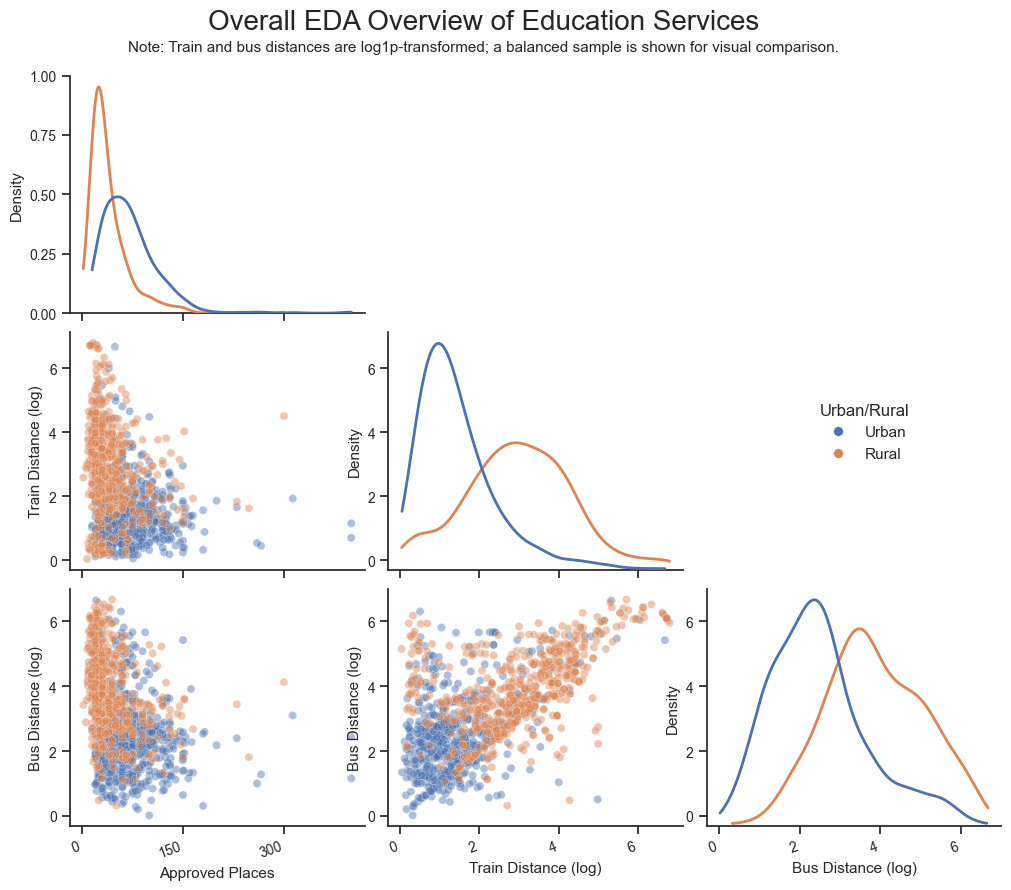

In [39]:
df = pd.read_csv("data/education_services_cleaned.csv", low_memory=False)
output_dir = "analysis_outputs"
figure_dir = os.path.join(output_dir, "figures")
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

plot_df = df[
    [
        "number_of_approved_places",
        "distance_to_train_station_km",
        "distance_to_bus_station_km",
        "urban_rural",
        "valid_spatial_record"
    ]
].copy()

plot_df = plot_df[plot_df["valid_spatial_record"] == True]
plot_df = plot_df.dropna(subset=[
    "number_of_approved_places",
    "distance_to_train_station_km",
    "distance_to_bus_station_km",
    "urban_rural"
])

plot_df = plot_df[plot_df["urban_rural"].isin(["Urban", "Rural"])]
plot_df["Approved Places"] = plot_df["number_of_approved_places"]
plot_df["Train Distance (log)"] = np.log1p(plot_df["distance_to_train_station_km"])
plot_df["Bus Distance (log)"] = np.log1p(plot_df["distance_to_bus_station_km"])
plot_df["Urban/Rural"] = plot_df["urban_rural"]

n_each = min(plot_df["Urban/Rural"].value_counts().min(), 600)
plot_df = pd.concat([
    plot_df[plot_df["Urban/Rural"] == "Urban"].sample(n=n_each, random_state=42),
    plot_df[plot_df["Urban/Rural"] == "Rural"].sample(n=n_each, random_state=42)
], ignore_index=True)

vars_list = ["Approved Places", "Train Distance (log)", "Bus Distance (log)"]
palette = {"Urban": "#4C72B0", "Rural": "#DD8452"}

sns.set_theme(
    style="ticks",
    context="notebook",
    font_scale=1.0,
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white"
    }
)

g = sns.PairGrid(
    plot_df,
    vars=vars_list,
    hue="Urban/Rural",
    hue_order=["Urban", "Rural"],
    corner=True,
    palette=palette,
    height=3.8,
    aspect=1.05,
    diag_sharey=False
)

g.map_lower(
    sns.scatterplot,
    alpha=0.45,
    s=34,
    edgecolor="white",
    linewidth=0.35
)

g.map_diag(
    sns.kdeplot,
    fill=False,
    common_norm=False,
    cut=0,
    bw_adjust=1.1,
    linewidth=2
)

g.fig.set_size_inches(11.5, 9.5)
g.fig.subplots_adjust(
    top=0.91,
    right=0.95,
    left=0.14,  
    bottom=0.12,
    wspace=0.08,
    hspace=0.08
)

g.fig.suptitle(
    "Overall EDA Overview of Education Services",
    fontsize=20,
    y=0.98
)

g.fig.text(
    0.5, 0.94,
    "Note: Train and bus distances are log1p-transformed; a balanced sample is shown for visual comparison.",
    ha="center",
    va="center",
    fontsize=11
)

n_vars = len(vars_list)

for i in range(n_vars):
    for j in range(n_vars):
        ax = g.axes[i, j]
        if ax is None:
            continue

        ax.tick_params(axis="both", labelsize=10)
        ax.tick_params(axis="y", labelleft=True, left=True)
        ax.get_yaxis().set_visible(True)
        ax.yaxis.label.set_visible(True)
        ax.yaxis.set_label_position("left")
        ax.yaxis.set_ticks_position("left")
        ax.spines["left"].set_visible(True)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
        ax.yaxis.set_major_locator(mticker.MaxNLocator(4))

        if i == j:
            ax.set_ylabel("Density", fontsize=11)
        else:
            ax.set_ylabel(vars_list[i], fontsize=11)

        if i == n_vars - 1:
            ax.set_xlabel(vars_list[j], fontsize=11)
        else:
            ax.set_xlabel("")

for ax in g.axes[-1, :]:
    if ax is not None:
        for label in ax.get_xticklabels():
            label.set_rotation(20)
            label.set_ha("right")

legend_handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='',
        markerfacecolor=palette["Urban"],
        markeredgecolor='white',
        markeredgewidth=0.35,
        markersize=7,
        label='Urban'
    ),
    Line2D(
        [0], [0],
        marker='o',
        linestyle='',
        markerfacecolor=palette["Rural"],
        markeredgecolor='white',
        markeredgewidth=0.35,
        markersize=7,
        label='Rural'
    )
]

g.fig.legend(
    handles=legend_handles,
    labels=["Urban", "Rural"],
    title="Urban/Rural",
    loc="upper left",
    bbox_to_anchor=(0.78, 0.58),
    frameon=False,
    fontsize=11,
    title_fontsize=12
)

g.fig.savefig(
    os.path.join(figure_dir, "eda_overview_pairgrid_final.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Part 2: Figure generates

As my main key business question is: **Which geographic areas and service scenarios face compounding disadvantages across  transport access, service quality, and operational capacity — and where should ACECQA direct its attention?** 

And to answer & focus it specifically, I will divided into four sub-key question & generate related figures for futher analysis:

- Where do transport, quality, and capacity disadvantages overlap geographically?
- Are public-transport access gaps structurally worse outside urban areas, and how do they differ by service type?
- In Centre-Based Care, where do poorer transport-access quartiles coincide with higher shares below Meeting NQS?
- In Centre-Based Care, does the urban–rural capacity gap persist across transport-access quartiles?

### Analysis scope check

As I want to foucus on areas and service contexts show overlapping disadvantages, it is important to check the if the data is suits for me to analysis this key business questions. Before plotting the figures, I checked sample size and variable completeness across service types and urban/rural groups.

In [40]:
gpkg_layer = "education_services_cleaned"
services_gdf = gpd.read_file(gpkg_path, layer=gpkg_layer)
for col in [
    "service_type",
    "state",
    "overall_rating",
    "urban_rural",
    "sos_name",
]:
    if col in services_gdf.columns:
        services_gdf[col] = services_gdf[col].astype("string").str.strip()

for col in [
    "distance_to_train_station_km",
    "distance_to_bus_station_km",
    "number_of_approved_places",
    "longitude",
    "latitude",
]:
    if col in services_gdf.columns:
        services_gdf[col] = pd.to_numeric(services_gdf[col], errors="coerce")

if "service_approval_granted_date" in services_gdf.columns:
    services_gdf["service_approval_granted_date"] = pd.to_datetime(
        services_gdf["service_approval_granted_date"], errors="coerce"
    )


services_gdf["nearest_public_transport_km"] = services_gdf[
    ["distance_to_train_station_km", "distance_to_bus_station_km"]
].min(axis=1, skipna=True)

services_gdf.loc[
    services_gdf[["distance_to_train_station_km", "distance_to_bus_station_km"]].isna().all(axis=1),
    "nearest_public_transport_km",
] = np.nan

services_gdf.loc[
    services_gdf["nearest_public_transport_km"] < 0,
    "nearest_public_transport_km",
] = np.nan

services_gdf["overall_rating_binary"] = pd.NA
services_gdf.loc[
    services_gdf["overall_rating"].isin(["Meeting NQS", "Exceeding NQS", "Excellent"]),
    "overall_rating_binary",
] = "Meeting NQS or Above"
services_gdf.loc[
    services_gdf["overall_rating"].isin(["Working Towards NQS", "Significant Improvement Required"]),
    "overall_rating_binary",
] = "Below Meeting NQS"

services_gdf["below_meeting_flag"] = pd.NA
services_gdf.loc[
    services_gdf["overall_rating_binary"].eq("Meeting NQS or Above"),
    "below_meeting_flag",
] = 0
services_gdf.loc[
    services_gdf["overall_rating_binary"].eq("Below Meeting NQS"),
    "below_meeting_flag",
] = 1
services_gdf["below_meeting_flag"] = pd.to_numeric(services_gdf["below_meeting_flag"], errors="coerce")

services_gdf["service_age_years"] = (
    (pd.Timestamp.today().normalize() - services_gdf["service_approval_granted_date"]).dt.days / 365.25
)

analysis_gdf = services_gdf.copy()

analysis_gdf = analysis_gdf.loc[
    analysis_gdf["valid_spatial_record"].fillna(False)
    & analysis_gdf["spatial_join_success"].fillna(False)
].copy()

analysis_gdf = analysis_gdf.loc[
    analysis_gdf["urban_rural"].isin(["Urban", "Rural"])
].copy()

analysis_gdf = analysis_gdf.loc[
    analysis_gdf["service_type"].isin(["Centre-Based Care", "Family Day Care"])
].copy()

analysis_gdf = analysis_gdf.loc[
    analysis_gdf["nearest_public_transport_km"].notna()
    & analysis_gdf["overall_rating_binary"].notna()
].copy()

analysis_gdf["transport_access_quartile"] = pd.qcut(
    analysis_gdf["nearest_public_transport_km"],
    q=4,
    labels=["Q1 Closest", "Q2", "Q3", "Q4 Farthest"],
    duplicates="drop",
)

quartile_order = ["Q1 Closest", "Q2", "Q3", "Q4 Farthest"]

sample_scope_summary = (
    analysis_gdf.groupby(["urban_rural", "service_type"])
    .agg(
        analysis_service_count=("service_type", "size"),
        approved_places_non_missing=("number_of_approved_places", lambda x: x.notna().sum()),
        approved_places_missing=("number_of_approved_places", lambda x: x.isna().sum()),
        median_transport_km=("nearest_public_transport_km", "median"),
        below_meeting_rate=("below_meeting_flag", "mean"),
    )
    .reset_index()
    .sort_values(["urban_rural", "service_type"])
)

service_type_overall_summary = (
    analysis_gdf.groupby("service_type")
    .agg(
        analysis_service_count=("service_type", "size"),
        approved_places_non_missing=("number_of_approved_places", lambda x: x.notna().sum()),
        approved_places_missing=("number_of_approved_places", lambda x: x.isna().sum()),
    )
    .reset_index()
    .sort_values("service_type")
)

urban_cbc_n = int(
    sample_scope_summary.loc[
        (sample_scope_summary["urban_rural"].eq("Urban"))
        & (sample_scope_summary["service_type"].eq("Centre-Based Care")),
        "analysis_service_count"
    ].iloc[0]
)

rural_cbc_n = int(
    sample_scope_summary.loc[
        (sample_scope_summary["urban_rural"].eq("Rural"))
        & (sample_scope_summary["service_type"].eq("Centre-Based Care")),
        "analysis_service_count"
    ].iloc[0]
)

urban_fdc_n = int(
    sample_scope_summary.loc[
        (sample_scope_summary["urban_rural"].eq("Urban"))
        & (sample_scope_summary["service_type"].eq("Family Day Care")),
        "analysis_service_count"
    ].iloc[0]
)

rural_fdc_n = int(
    sample_scope_summary.loc[
        (sample_scope_summary["urban_rural"].eq("Rural"))
        & (sample_scope_summary["service_type"].eq("Family Day Care")),
        "analysis_service_count"
    ].iloc[0]
)

cbc_capacity_non_missing = int(
    service_type_overall_summary.loc[
        service_type_overall_summary["service_type"].eq("Centre-Based Care"),
        "approved_places_non_missing"
    ].iloc[0]
)

fdc_capacity_non_missing = int(
    service_type_overall_summary.loc[
        service_type_overall_summary["service_type"].eq("Family Day Care"),
        "approved_places_non_missing"
    ].iloc[0]
)

focus_service_type = "Centre-Based Care"
fdc_rural_small_sample_flag = rural_fdc_n < 30
fdc_capacity_sparse_flag = fdc_capacity_non_missing < 30

print("=" * 45)
print("PRE-CHART SAMPLE-SIZE CHECK BY URBAN/RURAL AND SERVICE TYPE")
print("=" * 45)
print(sample_scope_summary.to_string(index=False))


PRE-CHART SAMPLE-SIZE CHECK BY URBAN/RURAL AND SERVICE TYPE
urban_rural      service_type  analysis_service_count  approved_places_non_missing  approved_places_missing  median_transport_km  below_meeting_rate
      Rural Centre-Based Care                    1025                         1025                        0            17.096440            0.122927
      Rural   Family Day Care                      12                            0                       12            16.883416            0.166667
      Urban Centre-Based Care                   14946                        14944                        2             2.131078            0.085642
      Urban   Family Day Care                     343                            0                      343             1.822719            0.224490


Based on above output, we can see that **Centre-Based Care** has a much larger and more reliable sample than **Family Day Care**:

- Urban | Centre-Based Care: 14,946 
- Rural | Centre-Based Care: 1,025 
- Urban | Family Day Care: 343 
- Rural | Family Day Care: 12 

In [41]:
print("\n" + "=" * 45)
print("OVERALL SERVICE-TYPE CHECK")
print("=" * 45)
print(service_type_overall_summary.to_string(index=False))


OVERALL SERVICE-TYPE CHECK
     service_type  analysis_service_count  approved_places_non_missing  approved_places_missing
Centre-Based Care                   15971                        15969                        2
  Family Day Care                     355                            0                      355


The overall service-type check shows that Centre-Based Care dominates the usable analysis sample, with 15,971 services compared with only 355 Family Day Care services. More importantly, approved places are almost fully available for Centre-Based Care (15,969 non-missing) but completely missing for Family Day Care (0 non-missing).

In [42]:
print("\n" + "=" * 45)
print("KEY COUNTS USED TO SET ANALYSIS SCOPE")
print("=" * 45)
print(f"Urban | Centre-Based Care: {urban_cbc_n}")
print(f"Rural | Centre-Based Care: {rural_cbc_n}")
print(f"Urban | Family Day Care: {urban_fdc_n}")
print(f"Rural | Family Day Care: {rural_fdc_n}")
print(f"Centre-Based Care approved places non-missing: {cbc_capacity_non_missing}")
print(f"Family Day Care approved places non-missing: {fdc_capacity_non_missing}")
print(f"fdc_rural_small_sample_flag: {fdc_rural_small_sample_flag}")
print(f"fdc_capacity_sparse_flag: {fdc_capacity_sparse_flag}")


KEY COUNTS USED TO SET ANALYSIS SCOPE
Urban | Centre-Based Care: 14946
Rural | Centre-Based Care: 1025
Urban | Family Day Care: 343
Rural | Family Day Care: 12
Centre-Based Care approved places non-missing: 15969
Family Day Care approved places non-missing: 0
fdc_rural_small_sample_flag: True
fdc_capacity_sparse_flag: True


From above we can see that family Day Care has a much smaller rural sample (Urban n=343, Rural n=12) than Centre-Based Care (Urban n=14946, Rural n=1025). Approved places are also largely unavailable for Family Day Care (non-missing approved places: Centre-Based Care=15969, Family Day Care=0). Therefore for a responsible analysis, the main analysis will be focuses on **Centre-Based Care**.

#### Figure generate

In [43]:
# -------------------------------------------------------------------
# Chart 1: Interactive triple-gap hotspot map
# In-map buttons + clickable legend filters
# -------------------------------------------------------------------

warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

analysis_scope_df = analysis_gdf.loc[
    analysis_gdf["service_type"].eq(focus_service_type)
].copy()

map_gdf = analysis_scope_df.loc[
    analysis_scope_df["number_of_approved_places"].notna()
].copy()

poor_access_cutoff = map_gdf["nearest_public_transport_km"].quantile(0.75)
low_capacity_cutoff = map_gdf["number_of_approved_places"].quantile(0.25)

map_gdf["poor_access_flag"] = (
    map_gdf["nearest_public_transport_km"] >= poor_access_cutoff
)

map_gdf["weak_quality_flag"] = (
    map_gdf["overall_rating_binary"].eq("Below Meeting NQS")
)

map_gdf["low_capacity_flag"] = (
    map_gdf["number_of_approved_places"] <= low_capacity_cutoff
)

map_gdf["gap_score"] = (
    map_gdf["poor_access_flag"].astype(int)
    + map_gdf["weak_quality_flag"].astype(int)
    + map_gdf["low_capacity_flag"].astype(int)
)

map_gdf["gap_label"] = pd.NA
map_gdf.loc[map_gdf["gap_score"] == 0, "gap_label"] = "0 gaps"
map_gdf.loc[map_gdf["gap_score"] == 1, "gap_label"] = "1 gap"
map_gdf.loc[map_gdf["gap_score"] == 2, "gap_label"] = "2 gaps"
map_gdf.loc[map_gdf["gap_score"] == 3, "gap_label"] = "3 gaps"

hotspot_summary = (
    map_gdf.groupby(["state", "urban_rural", "gap_label"])
    .size()
    .reset_index(name="service_count")
    .sort_values(["state", "urban_rural", "gap_label"])
)

analysis_total = int(len(analysis_scope_df))
two_gap_count = int((map_gdf["gap_score"] == 2).sum())
three_gap_count = int((map_gdf["gap_score"] == 3).sum())

triple_gap_df = map_gdf.loc[map_gdf["gap_score"] == 3].copy()

triple_by_urban_rural = triple_gap_df.groupby("urban_rural").size()
denom_by_urban_rural = analysis_scope_df.groupby("urban_rural").size()

urban_triple_count = int(triple_by_urban_rural.get("Urban", 0))
rural_triple_count = int(triple_by_urban_rural.get("Rural", 0))

urban_total = int(denom_by_urban_rural.get("Urban", 0))
rural_total = int(denom_by_urban_rural.get("Rural", 0))

urban_triple_rate = urban_triple_count / urban_total if urban_total else np.nan
rural_triple_rate = rural_triple_count / rural_total if rural_total else np.nan

top_state_counts = (
    triple_gap_df.groupby("state")
    .size()
    .sort_values(ascending=False)
)

focus_states = ["SA", "QLD", "NSW", "WA"]

chart1_key_metrics = pd.DataFrame(
    {
        "metric": [
            "analysis_total_centre_based_care",
            "two_gap_services",
            "three_gap_services",
            "urban_three_gap_services",
            "urban_three_gap_rate",
            "rural_three_gap_services",
            "rural_three_gap_rate",
            "poor_access_cutoff_km",
            "low_capacity_cutoff_places",
        ],
        "value": [
            analysis_total,
            two_gap_count,
            three_gap_count,
            urban_triple_count,
            urban_triple_rate,
            rural_triple_count,
            rural_triple_rate,
            poor_access_cutoff,
            low_capacity_cutoff,
        ],
    }
)

background_df = analysis_scope_df.loc[
    analysis_scope_df.geometry.notna()
].copy()

hotspot_2 = map_gdf.loc[
    (map_gdf["gap_score"] == 2) & map_gdf.geometry.notna()
].copy()

hotspot_3 = map_gdf.loc[
    (map_gdf["gap_score"] == 3) & map_gdf.geometry.notna()
].copy()

urban_3 = hotspot_3.loc[hotspot_3["urban_rural"] == "Urban"].copy()
rural_3 = hotspot_3.loc[hotspot_3["urban_rural"] == "Rural"].copy()

state_traces = {}
for st in focus_states:
    state_traces[st] = hotspot_3.loc[hotspot_3["state"] == st].copy()

def build_hover_text(df):
    return (
        "<b>" + df["service_name"].fillna("Unknown service").astype(str) + "</b><br>"
        + "State: " + df["state"].fillna("NA").astype(str) + "<br>"
        + "Urban/Rural: " + df["urban_rural"].fillna("NA").astype(str) + "<br>"
        + "Rating: " + df["overall_rating"].fillna("NA").astype(str) + "<br>"
        + "Nearest PT: " + df["nearest_public_transport_km"].round(2).astype(str) + " km<br>"
        + "Approved places: " + df["number_of_approved_places"].round(0).astype("Int64").astype(str) + "<br>"
        + "<b>Gap label: " + df["gap_label"].fillna("NA").astype(str) + "</b><br>"
        + "Poor access gap: " + df["poor_access_flag"].map({True: "Yes", False: "No"}).astype(str) + "<br>"
        + "Quality gap: " + df["weak_quality_flag"].map({True: "Yes", False: "No"}).astype(str) + "<br>"
        + "Capacity gap: " + df["low_capacity_flag"].map({True: "Yes", False: "No"}).astype(str)
    )

hotspot_2["hover_text"] = build_hover_text(hotspot_2)
hotspot_3["hover_text"] = build_hover_text(hotspot_3)
urban_3["hover_text"] = build_hover_text(urban_3)
rural_3["hover_text"] = build_hover_text(rural_3)

for st in focus_states:
    state_traces[st]["hover_text"] = build_hover_text(state_traces[st])

center_lat = float(
    (background_df.geometry.y.min() + background_df.geometry.y.max()) / 2
)
center_lon = float(
    (background_df.geometry.x.min() + background_df.geometry.x.max()) / 2
)

fig = go.Figure()
fig.add_trace(
    go.Scattermap(
        lat=background_df.geometry.y,
        lon=background_df.geometry.x,
        mode="markers",
        marker=dict(
            size=4,
            color="lightgrey",
            opacity=0.20
        ),
        hoverinfo="skip",
        name="All Centre-Based Care services",
        showlegend=False
    )
)

fig.add_trace(
    go.Scattermap(
        lat=hotspot_2.geometry.y,
        lon=hotspot_2.geometry.x,
        mode="markers",
        marker=dict(
            size=9,
            color="#4F81BD",
            opacity=0.82
        ),
        text=hotspot_2["hover_text"],
        hovertemplate="%{text}<extra></extra>",
        name=f"2 gaps ({two_gap_count:,})",
        legendgroup="gap",
        visible=True
    )
)

fig.add_trace(
    go.Scattermap(
        lat=hotspot_3.geometry.y,
        lon=hotspot_3.geometry.x,
        mode="markers",
        marker=dict(
            size=13,
            color="#57B8CC",
            opacity=0.92
        ),
        text=hotspot_3["hover_text"],
        hovertemplate="%{text}<extra></extra>",
        name=f"3 gaps ({three_gap_count:,})",
        legendgroup="gap",
        visible=True
    )
)

fig.add_trace(
    go.Scattermap(
        lat=urban_3.geometry.y,
        lon=urban_3.geometry.x,
        mode="markers",
        marker=dict(
            size=13,
            color="#1F77B4",
            opacity=0.95
        ),
        text=urban_3["hover_text"],
        hovertemplate="%{text}<extra></extra>",
        name=f"Urban 3 gaps ({urban_triple_count}, {urban_triple_rate:.1%} of urban CBC)",
        legendgroup="urban_rural",
        visible="legendonly"
    )
)

fig.add_trace(
    go.Scattermap(
        lat=rural_3.geometry.y,
        lon=rural_3.geometry.x,
        mode="markers",
        marker=dict(
            size=13,
            color="#FF7F0E",
            opacity=0.95
        ),
        text=rural_3["hover_text"],
        hovertemplate="%{text}<extra></extra>",
        name=f"Rural 3 gaps ({rural_triple_count}, {rural_triple_rate:.1%} of rural CBC)",
        legendgroup="urban_rural",
        visible="legendonly"
    )
)

state_colors = {
    "SA": "#7F3C8D",
    "QLD": "#11A579",
    "NSW": "#3969AC",
    "WA": "#F2B701"
}

for st in focus_states:
    count_st = int(top_state_counts.get(st, 0))
    df_st = state_traces[st]

    fig.add_trace(
        go.Scattermap(
            lat=df_st.geometry.y,
            lon=df_st.geometry.x,
            mode="markers",
            marker=dict(
                size=14,
                color=state_colors.get(st, "#444444"),
                opacity=0.95
            ),
            text=df_st["hover_text"],
            hovertemplate="%{text}<extra></extra>",
            name=f"{st}: {count_st}",
            legendgroup="states",
            visible="legendonly"
        )
    )

fig.update_layout(
    title=dict(
        text=(
            "Chart 1. Triple-gap hotspot services<br>"
            "<sup>Poor transport access + below Meeting NQS + low approved places | "
            "Centre-Based Care only</sup>"
        ),
        x=0.5,
        y=0.98,
        xanchor="center",
        yanchor="top",
        font=dict(size=22, color="#0B1F5D")
    ),
    hovermode="closest",
    map=dict(
        style="light",
        center=dict(lat=center_lat, lon=center_lon),
        zoom=2.75
    ),
    margin=dict(l=10, r=10, t=105, b=10),
    paper_bgcolor="white",
    plot_bgcolor="white",
    showlegend=False,
)

initial_visibility = [
    True,   # 0 background
    True,   # 1 2 gaps
    True,   # 2 3 gaps
    False,  # 3 Urban 3 gaps
    False,  # 4 Rural 3 gaps
    False,  # 5 SA
    False,  # 6 QLD
    False,  # 7 NSW
    False,  # 8 WA
]

for i, visible in enumerate(initial_visibility):
    if i < len(fig.data):
        fig.data[i].visible = visible
        fig.data[i].showlegend = False

chart1_html_path = os.path.join(
    figure_dir,
    "chart1_triple_gap_hotspots_map_interactive.html"
)

plot_div = fig.to_html(
    include_plotlyjs=True,
    full_html=False,
    div_id="chart1",
    default_width="100%",
    default_height="95vh",
    config={
        "scrollZoom": True,
        "displayModeBar": True,
        "responsive": True
    }
)

custom_html = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<title>Chart 1 Triple-gap Hotspot Map</title>

<style>
    html, body {{
        margin: 0;
        padding: 0;
        width: 100%;
        height: 100%;
        font-family: Arial, Helvetica, sans-serif;
        background: white;
        overflow: hidden;
    }}

    #chart1-wrapper {{
        position: relative;
        width: 100%;
        height: 95vh;
    }}

    #chart1 {{
        width: 100% !important;
        height: 95vh !important;
    }}

    .floating-box {{
        position: absolute;
        z-index: 9999;
        background: rgba(255, 255, 255, 0.92);
        border: 1px solid rgba(0, 0, 0, 0.22);
        box-shadow: 0 1px 2px rgba(0, 0, 0, 0.08);
        color: #23395B;
    }}

    /* 
       These three top values mimic your original Plotly spacing:
       buttons near y=0.985, sample near y=0.885, layer box near y=0.785.
       If you want to fine tune spacing later, only adjust these three values.
    */
    .mode-controls {{
        left: 2%;
        top: 11.5%;
        display: flex;
        gap: 4px;
        background: transparent;
        border: none;
        box-shadow: none;
    }}

    .sample-panel {{
        left: 2%;
        top: 17.0%;
        padding: 8px 11px;
        font-size: 13px;
        line-height: 1.25;
        min-width: 610px;
        max-width: 760px;
    }}

    .layer-panel {{
        left: 2%;
        top: 25.5%;
        padding: 10px 13px;
        min-width: 370px;
        max-width: 560px;
    }}

    .mode-button {{
        font-size: 14px;
        color: #23395B;
        background: rgba(255, 255, 255, 0.92);
        border: 1px solid rgba(0, 0, 0, 0.25);
        border-radius: 4px;
        padding: 8px 14px;
        cursor: pointer;
        line-height: 1.15;
    }}

    .mode-button.active {{
        background: #EAF2F8;
        border-color: #7F9DB9;
        font-weight: 700;
    }}

    .panel-title {{
        font-size: 15px;
        margin-bottom: 9px;
        color: #23395B;
        line-height: 1.2;
    }}

    .checkbox-row {{
        display: flex;
        align-items: center;
        gap: 8px;
        margin: 7px 0;
        font-size: 13.5px;
        color: #23395B;
        cursor: pointer;
        user-select: none;
        line-height: 1.2;
    }}

    .checkbox-row input {{
        width: 13px;
        height: 13px;
        cursor: pointer;
        margin: 0;
    }}

    .dot {{
        width: 11px;
        height: 11px;
        border-radius: 50%;
        display: inline-block;
        flex: 0 0 11px;
    }}

    .section-gap {{
        height: 5px;
    }}

    .small-note {{
        font-size: 11.5px;
        color: #56657A;
        margin-top: 6px;
        line-height: 1.25;
    }}
</style>
</head>

<body>
<div id="chart1-wrapper">

    {plot_div}

    <div class="mode-controls floating-box">
        <button id="btn-both" class="mode-button active">Show 2 + 3 gaps</button>
        <button id="btn-three" class="mode-button">Show 3 gaps only</button>
    </div>

    <div class="sample-panel floating-box">
        <b>Analysis sample:</b> {analysis_total:,} Centre-Based Care services<br>
        <b>2-gap:</b> {two_gap_count:,} | <b>3-gap:</b> {three_gap_count:,}<br>
        <i>Tip:</i> Use the checkboxes below to show or hide hotspot layers.
    </div>

    <div id="layer-panel-basic" class="layer-panel floating-box">
        <div class="panel-title">Click below to show / hide hotspot groups</div>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-gap2-basic" checked>
            <span class="dot" style="background:#4F81BD;"></span>
            <span>2 gaps ({two_gap_count:,})</span>
        </label>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-gap3-basic" checked>
            <span class="dot" style="background:#57B8CC;"></span>
            <span>3 gaps ({three_gap_count:,})</span>
        </label>
    </div>

    <div id="layer-panel-detail" class="layer-panel floating-box" style="display:none;">
        <div class="panel-title">Click below to show / hide specific hotspots</div>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-gap3-detail" checked>
            <span class="dot" style="background:#57B8CC;"></span>
            <span>3 gaps ({three_gap_count:,})</span>
        </label>

        <div class="section-gap"></div>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-urban">
            <span class="dot" style="background:#1F77B4;"></span>
            <span>Urban 3 gaps ({urban_triple_count}, {urban_triple_rate:.1%} of urban CBC)</span>
        </label>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-rural">
            <span class="dot" style="background:#FF7F0E;"></span>
            <span>Rural 3 gaps ({rural_triple_count}, {rural_triple_rate:.1%} of rural CBC)</span>
        </label>

        <div class="section-gap"></div>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-sa">
            <span class="dot" style="background:#7F3C8D;"></span>
            <span>SA: {int(top_state_counts.get("SA", 0))}</span>
        </label>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-qld">
            <span class="dot" style="background:#11A579;"></span>
            <span>QLD: {int(top_state_counts.get("QLD", 0))}</span>
        </label>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-nsw">
            <span class="dot" style="background:#3969AC;"></span>
            <span>NSW: {int(top_state_counts.get("NSW", 0))}</span>
        </label>

        <label class="checkbox-row">
            <input type="checkbox" id="cb-wa">
            <span class="dot" style="background:#F2B701;"></span>
            <span>WA: {int(top_state_counts.get("WA", 0))}</span>
        </label>

        <div class="small-note">
            Selecting a specific layer automatically hides the full 3-gap layer for clearer comparison.
        </div>
    </div>

</div>

<script>
window.addEventListener("load", function () {{

    const CHART_ID = "chart1";

    // Trace order must match the order in which traces were added in Python.
    const TRACE = {{
        background: 0,
        gap2: 1,
        gap3: 2,
        urban: 3,
        rural: 4,
        SA: 5,
        QLD: 6,
        NSW: 7,
        WA: 8
    }};

    const detailTraceIds = [
        TRACE.urban,
        TRACE.rural,
        TRACE.SA,
        TRACE.QLD,
        TRACE.NSW,
        TRACE.WA
    ];

    const detailCheckboxIds = [
        "cb-urban",
        "cb-rural",
        "cb-sa",
        "cb-qld",
        "cb-nsw",
        "cb-wa"
    ];

    function setTrace(traceIndex, isVisible) {{
        Plotly.restyle(CHART_ID, {{ visible: isVisible }}, [traceIndex]);
    }}

    function setCheckbox(id, checked) {{
        const el = document.getElementById(id);
        if (el) {{
            el.checked = checked;
        }}
    }}

    function hideAllDetailLayers() {{
        detailTraceIds.forEach(function (traceId) {{
            setTrace(traceId, false);
        }});
        detailCheckboxIds.forEach(function (id) {{
            setCheckbox(id, false);
        }});
    }}

    function setActiveMode(mode) {{
        const btnBoth = document.getElementById("btn-both");
        const btnThree = document.getElementById("btn-three");

        if (mode === "both") {{
            btnBoth.classList.add("active");
            btnThree.classList.remove("active");
        }} else {{
            btnBoth.classList.remove("active");
            btnThree.classList.add("active");
        }}
    }}

    function showBothMode() {{
        setActiveMode("both");

        document.getElementById("layer-panel-basic").style.display = "block";
        document.getElementById("layer-panel-detail").style.display = "none";

        setTrace(TRACE.background, true);
        setTrace(TRACE.gap2, true);
        setTrace(TRACE.gap3, true);

        hideAllDetailLayers();

        setCheckbox("cb-gap2-basic", true);
        setCheckbox("cb-gap3-basic", true);
        setCheckbox("cb-gap3-detail", true);
    }}

    function showThreeOnlyMode() {{
        setActiveMode("three");

        document.getElementById("layer-panel-basic").style.display = "none";
        document.getElementById("layer-panel-detail").style.display = "block";

        setTrace(TRACE.background, true);
        setTrace(TRACE.gap2, false);
        setTrace(TRACE.gap3, true);

        hideAllDetailLayers();

        setCheckbox("cb-gap3-detail", true);
    }}

    function selectSpecificLayer(traceIndex, checkboxId) {{
        const checkbox = document.getElementById(checkboxId);

        checkbox.addEventListener("change", function () {{
            if (checkbox.checked) {{
                // Hide full 3-gap layer when a specific subgroup is selected.
                setTrace(TRACE.gap3, false);
                setCheckbox("cb-gap3-detail", false);

                setTrace(traceIndex, true);
            }} else {{
                setTrace(traceIndex, false);
            }}
        }});
    }}

    // Top mode buttons
    document.getElementById("btn-both").addEventListener("click", showBothMode);
    document.getElementById("btn-three").addEventListener("click", showThreeOnlyMode);

    // Basic mode checkboxes
    document.getElementById("cb-gap2-basic").addEventListener("change", function () {{
        setTrace(TRACE.gap2, this.checked);
    }});

    document.getElementById("cb-gap3-basic").addEventListener("change", function () {{
        setTrace(TRACE.gap3, this.checked);
    }});

    // Detail mode full 3-gap checkbox
    document.getElementById("cb-gap3-detail").addEventListener("change", function () {{
        setTrace(TRACE.gap3, this.checked);

        if (this.checked) {{
            hideAllDetailLayers();
            setCheckbox("cb-gap3-detail", true);
        }}
    }});

    // Detail mode specific layers
    selectSpecificLayer(TRACE.urban, "cb-urban");
    selectSpecificLayer(TRACE.rural, "cb-rural");
    selectSpecificLayer(TRACE.SA, "cb-sa");
    selectSpecificLayer(TRACE.QLD, "cb-qld");
    selectSpecificLayer(TRACE.NSW, "cb-nsw");
    selectSpecificLayer(TRACE.WA, "cb-wa");

    // Ensure initial state is correct.
    showBothMode();
}});
</script>

</body>
</html>
"""

with open(chart1_html_path, "w", encoding="utf-8") as f:
    f.write(custom_html)

print("Interactive Chart 1 saved to:", chart1_html_path)

# Chart2: Boxplot of nearest public transport distance by urban/rural and service type
box_df = analysis_gdf.copy()

box_df = box_df.loc[
    box_df["urban_rural"].notna()
    & box_df["service_type"].notna()
    & box_df["nearest_public_transport_km"].notna()
    & box_df["nearest_public_transport_km"].gt(0)
].copy()

box_df["box_group"] = (
    box_df["urban_rural"].astype(str)
    + " | "
    + box_df["service_type"].astype(str)
)

box_order = [
    "Urban | Centre-Based Care",
    "Urban | Family Day Care",
    "Rural | Centre-Based Care",
    "Rural | Family Day Care",
]

box_df = box_df.loc[box_df["box_group"].isin(box_order)].copy()
box_summary = (
    box_df.groupby(["urban_rural", "service_type"], dropna=False)
    .agg(
        median_distance_km=("nearest_public_transport_km", "median"),
        p25_distance_km=("nearest_public_transport_km", lambda x: x.quantile(0.25)),
        p75_distance_km=("nearest_public_transport_km", lambda x: x.quantile(0.75)),
        min_distance_km=("nearest_public_transport_km", "min"),
        max_distance_km=("nearest_public_transport_km", "max"),
        service_count=("nearest_public_transport_km", "count"),
    )
    .reset_index()
)

box_summary["box_group"] = (
    box_summary["urban_rural"].astype(str)
    + " | "
    + box_summary["service_type"].astype(str)
)

box_summary = (
    box_summary.set_index("box_group")
    .reindex(box_order)
    .reset_index()
)

urban_cbc = box_summary.loc[
    box_summary["box_group"].eq("Urban | Centre-Based Care")
].iloc[0]

rural_cbc = box_summary.loc[
    box_summary["box_group"].eq("Rural | Centre-Based Care")
].iloc[0]

urban_fdc = box_summary.loc[
    box_summary["box_group"].eq("Urban | Family Day Care")
].iloc[0]

rural_fdc = box_summary.loc[
    box_summary["box_group"].eq("Rural | Family Day Care")
].iloc[0]

box_df["service_name_label"] = (
    box_df["service_name"]
    .fillna("Unknown service")
    .astype(str)
)

box_df["state_label"] = (
    box_df["state"]
    .fillna("NA")
    .astype(str)
)

box_df["rating_label"] = (
    box_df["overall_rating"]
    .fillna("NA")
    .astype(str)
)

box_df["approved_places_label"] = (
    box_df["number_of_approved_places"]
    .round(0)
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)

box_df["train_station_label"] = (
    box_df["closest_train_station"]
    .fillna("NA")
    .astype(str)
)

box_df["bus_station_label"] = (
    box_df["closest_bus_station"]
    .fillna("NA")
    .astype(str)
)

def hex_to_rgba(hex_color, alpha=0.20):
    hex_color = hex_color.lstrip("#")
    r, g, b = tuple(int(hex_color[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r}, {g}, {b}, {alpha})"

group_positions = {
    group_name: i + 1 for i, group_name in enumerate(box_order)
}

group_colors = {
    "Urban | Centre-Based Care": "#1f77b4",
    "Urban | Family Day Care": "#8fb9dd",
    "Rural | Centre-Based Care": "#ff7f0e",
    "Rural | Family Day Care": "#f5b27a",
}

fig = go.Figure()
rng = np.random.default_rng(42)

tick_vals = []
tick_text = []

for group_name in box_order:
    group_df = box_df.loc[box_df["box_group"].eq(group_name)].copy()

    if group_df.empty:
        continue

    x_pos = group_positions[group_name]
    trace_color = group_colors[group_name]

    n = len(group_df)
    median_val = group_df["nearest_public_transport_km"].median()
    q1_val = group_df["nearest_public_transport_km"].quantile(0.25)
    q3_val = group_df["nearest_public_transport_km"].quantile(0.75)
    min_val = group_df["nearest_public_transport_km"].min()
    max_val = group_df["nearest_public_transport_km"].max()

    tick_vals.append(x_pos)
    tick_text.append(f"{group_name}<br>(n={n:,})")
    fig.add_trace(
        go.Box(
            x=[x_pos] * n,
            y=group_df["nearest_public_transport_km"],
            name=group_name,
            boxpoints=False,
            width=0.45,
            marker=dict(color=trace_color),
            line=dict(color=trace_color, width=2),
            fillcolor=hex_to_rgba(trace_color, alpha=0.18),
            hovertemplate=(
                f"<b>{group_name}</b><br>"
                f"n: {n:,}<br>"
                f"Median: {median_val:.2f} km<br>"
                f"Q1: {q1_val:.2f} km<br>"
                f"Q3: {q3_val:.2f} km<br>"
                f"Min: {min_val:.2f} km<br>"
                f"Max: {max_val:.2f} km"
                "<extra></extra>"
            ),
            showlegend=False,
        )
    )

    x_jitter = x_pos + rng.normal(loc=0, scale=0.055, size=n)

    custom_data = group_df[
        [
            "service_name_label",
            "state_label",
            "urban_rural",
            "service_type",
            "rating_label",
            "approved_places_label",
            "train_station_label",
            "bus_station_label",
        ]
    ].to_numpy()

    point_opacity = 0.28
    if "Family Day Care" in group_name:
        point_opacity = 0.20

    fig.add_trace(
        go.Scattergl(
            x=x_jitter,
            y=group_df["nearest_public_transport_km"],
            mode="markers",
            marker=dict(
                color=trace_color,
                size=5,
                opacity=point_opacity,
            ),
            customdata=custom_data,
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "State: %{customdata[1]}<br>"
                "Urban/Rural: %{customdata[2]}<br>"
                "Service type: %{customdata[3]}<br>"
                "Rating: %{customdata[4]}<br>"
                "Nearest PT distance: %{y:.2f} km<br>"
                "Approved places: %{customdata[5]}<br>"
                "Closest train station: %{customdata[6]}<br>"
                "Closest bus station: %{customdata[7]}"
                "<extra></extra>"
            ),
            name=f"{group_name} services",
            visible=False,
            showlegend=False,
        )
    )

box_only_visibility = [
    True if i % 2 == 0 else False
    for i in range(len(fig.data))
]

show_points_visibility = [True] * len(fig.data)

box_only_js = json.dumps(box_only_visibility)
show_points_js = json.dumps(show_points_visibility)
trace_indices_js = json.dumps(list(range(len(fig.data))))
for i, visible in enumerate(show_points_visibility):
    fig.data[i].visible = visible

fig.update_layout(
    title=None,
    xaxis=dict(
        title="Urban/rural context and service type",
        tickmode="array",
        tickvals=tick_vals,
        ticktext=tick_text,
        range=[0.35, len(tick_vals) + 0.65],
    ),
    yaxis=dict(
        title="Nearest public transport distance (km, log scale)",
        type="log",
    ),
    hovermode="closest",
    autosize=True,
    margin=dict(l=80, r=55, t=25, b=120),
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
)

fig.update_xaxes(
    showgrid=False,
    zeroline=False,
)

fig.update_yaxes(
    showgrid=True,
    gridcolor="rgba(0,0,0,0.10)",
    zeroline=False,
)

chart2_html_path = os.path.join(
    figure_dir,
    "chart2_transport_disparity_boxplot_interactive.html"
)

plot_div = fig.to_html(
    include_plotlyjs=True,
    full_html=False,
    div_id="chart2",
    default_width="100%",
    default_height="100%",
    config={
        "scrollZoom": True,
        "displayModeBar": True,
        "responsive": True,
    },
)

custom_html = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<title>Chart 2 Transport Access Disparity</title>

<style>
    html, body {{
        margin: 0;
        padding: 0;
        width: 100%;
        height: 100%;
        font-family: Arial, Helvetica, sans-serif;
        background: white;
        color: #12315c;
        overflow: hidden;
    }}

    #chart2-wrapper {{
        width: 100vw;
        height: 100vh;
        min-height: 100vh;
        display: flex;
        flex-direction: column;
        background: white;
    }}

    .chart2-header {{
        flex: 0 0 auto;
        padding: 10px 64px 6px 64px;
        background: white;
        box-sizing: border-box;
    }}

    .chart2-title {{
        text-align: center;
        font-size: 22px;
        font-weight: 700;
        line-height: 1.15;
        margin: 0 0 3px 0;
        color: #12315c;
    }}

    .chart2-subtitle {{
        text-align: center;
        font-size: 13px;
        line-height: 1.2;
        margin: 0 0 9px 0;
        color: #12315c;
    }}

    .chart2-controls {{
        display: flex;
        gap: 4px;
        margin: 0 0 8px 0;
        align-items: center;
    }}

    .mode-button {{
        font-size: 12px;
        color: #12315c;
        background: rgba(255, 255, 255, 0.92);
        border: 1px solid rgba(0, 0, 0, 0.18);
        border-radius: 3px;
        padding: 7px 11px;
        cursor: pointer;
        line-height: 1.15;
    }}

    .mode-button.active {{
        background: #EAF2F8;
        border-color: #7F9DB9;
        font-weight: 700;
    }}

    .summary-card {{
        display: inline-block;
        background: rgba(255, 255, 255, 0.94);
        border: 1px solid rgba(0, 0, 0, 0.18);
        padding: 8px 10px;
        font-size: 12px;
        line-height: 1.25;
        color: #12315c;
        max-width: 780px;
        box-sizing: border-box;
    }}

    .plot-container {{
        flex: 1 1 auto;
        min-height: 0;
        width: 100%;
        height: 100%;
        background: white;
        overflow: hidden;
    }}
    .plot-container > div {{
        width: 100% !important;
        height: 100% !important;
        min-height: 0;
    }}

    #chart2 {{
        width: 100% !important;
        height: 100% !important;
    }}
</style>
</head>

<body>
<div id="chart2-wrapper">

    <div class="chart2-header">
        <div class="chart2-title">
            Chart 2. Are public-transport access gaps structurally worse outside urban areas?
        </div>

        <div class="chart2-subtitle">
            Comparison by urban/rural context and service type
            &nbsp;|&nbsp; Log scale used because transport distances are highly skewed
        </div>

        <div class="chart2-controls">
            <button id="btn-box-only" class="mode-button">Box only</button>
            <button id="btn-points" class="mode-button active">Show service points (detail view)</button>  
        </div>

        <div class="summary-card">
            <b>Key structural comparison: Centre-Based Care</b><br>
            Urban median = <b>{urban_cbc['median_distance_km']:.2f} km</b>
            &nbsp;|&nbsp;
            Rural median = <b>{rural_cbc['median_distance_km']:.2f} km</b><br>
            Rural Q1 = <b> 6.54 km</b>
            &gt;
            Urban Q3 = <b>{urban_cbc['p75_distance_km']:.2f} km</b>
            &nbsp;→&nbsp;
            the rural gap reflects a distribution-wide shift, not just outliers.<br>
            <i>Family Day Care is shown for context only; Rural Family Day Care n = {int(rural_fdc['service_count'])}.</i>
        </div>
    </div>

    <div class="plot-container">
        {plot_div}
    </div>

</div>

<script>
window.addEventListener("load", function () {{

    const CHART_ID = "chart2";
    const traceIndices = {trace_indices_js};
    const boxOnlyVisibility = {box_only_js};
    const showPointsVisibility = {show_points_js};

    const btnBoxOnly = document.getElementById("btn-box-only");
    const btnPoints = document.getElementById("btn-points");

    function setActiveButton(mode) {{
        if (mode === "box") {{
            btnBoxOnly.classList.add("active");
            btnPoints.classList.remove("active");
        }} else {{
            btnBoxOnly.classList.remove("active");
            btnPoints.classList.add("active");
        }}
    }}

    function setVisibility(visibilityArray) {{
        traceIndices.forEach(function(traceIndex, i) {{
            Plotly.restyle(CHART_ID, {{ visible: visibilityArray[i] }}, [traceIndex]);
        }});
    }}

    btnBoxOnly.addEventListener("click", function () {{
        setActiveButton("box");
        setVisibility(boxOnlyVisibility);
    }});

    btnPoints.addEventListener("click", function () {{
        setActiveButton("points");
        setVisibility(showPointsVisibility);
    }});

    // Ensure default view is correct.
    setActiveButton("points");
    setVisibility(showPointsVisibility);

    // Keep the plot responsive inside the flex container.
    // Keep the plot responsive inside the flex container.
    function resizeChart() {{
        const gd = document.getElementById(CHART_ID);
        if (gd) {{
            Plotly.Plots.resize(gd);
        }}
    }}

    // Resize after initial rendering
    requestAnimationFrame(resizeChart);
    setTimeout(resizeChart, 100);
    setTimeout(resizeChart, 300);

    // Resize when browser window changes
    window.addEventListener("resize", resizeChart);

    // Resize when the flex plot container changes size
    const plotContainer = document.querySelector(".plot-container");
    if (plotContainer && "ResizeObserver" in window) {{
        const resizeObserver = new ResizeObserver(function () {{
            resizeChart();
        }});
        resizeObserver.observe(plotContainer);
    }}
    }});
</script>

</body>
</html>
"""

with open(chart2_html_path, "w", encoding="utf-8") as f:
    f.write(custom_html)

print("Interactive Chart 2 saved to:", chart2_html_path)

# Chart 3: Quality heatmap
# State-level quality comparison is shown for Centre-Based Care only to avoids unstable state-level cells for Family Day Care.
quality_df = analysis_gdf.loc[
    analysis_gdf["service_type"].eq(focus_service_type)
].copy()

quality_summary = (
    quality_df.groupby(["state", "transport_access_quartile"])
    .agg(
        below_meeting_rate=("below_meeting_flag", "mean"),
        service_count=("below_meeting_flag", "size"),
    )
    .reset_index()
)

quality_summary.loc[
    quality_summary["service_count"] < 20,
    "below_meeting_rate",
] = np.nan

quality_summary["transport_access_quartile"] = pd.Categorical(
    quality_summary["transport_access_quartile"],
    categories=quartile_order,
    ordered=True,
)

quality_summary = quality_summary.sort_values(["state", "transport_access_quartile"])

heatmap_pivot = quality_summary.pivot(
    index="state",
    columns="transport_access_quartile",
    values="below_meeting_rate",
).reindex(columns=quartile_order)

heatmap_values = heatmap_pivot.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    cmap="viridis",   
    vmin=0,
    vmax=0.40,       
)

ax.set_xticks(np.arange(len(heatmap_pivot.columns)))
ax.set_xticklabels(heatmap_pivot.columns)
ax.set_yticks(np.arange(len(heatmap_pivot.index)))
ax.set_yticklabels(heatmap_pivot.index)

for i in range(heatmap_values.shape[0]):
    for j in range(heatmap_values.shape[1]):
        value = heatmap_values[i, j]
        if pd.notna(value):
            text_color = "white" if value < 0.18 else "black"
            ax.text(
                j, i, f"{value:.1%}",
                ha="center", va="center",
                color=text_color,
                fontsize=12,
                fontweight="bold"
            )

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Share below Meeting NQS")

ax.set_title(
    "Chart 3. Weaker quality outcomes are more common in poorer transport-access quartiles\n"
    "Centre-Based Care only"
)

plt.tight_layout()
plt.savefig(
    os.path.join(figure_dir, "chart3_quality_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Chart 4: Operational capacity by transport access quartile and urban/rural
# Limited to Centre-Based Care because approved places are mostly missing for Family Day Care.

capacity_df = analysis_gdf.loc[
    analysis_gdf["service_type"].eq(focus_service_type)
    & analysis_gdf["number_of_approved_places"].notna()
].copy()

capacity_summary = (
    capacity_df.groupby(["transport_access_quartile", "urban_rural"])
    .agg(
        median_approved_places=("number_of_approved_places", "median"),
        mean_approved_places=("number_of_approved_places", "mean"),
        service_count=("number_of_approved_places", "size"),
    )
    .reset_index()
)

capacity_summary["transport_access_quartile"] = pd.Categorical(
    capacity_summary["transport_access_quartile"],
    categories=quartile_order,
    ordered=True,
)

capacity_summary = capacity_summary.sort_values(
    ["transport_access_quartile", "urban_rural"]
)

median_pivot = (
    capacity_summary.pivot(
        index="transport_access_quartile",
        columns="urban_rural",
        values="median_approved_places",
    )
    .reindex(quartile_order)
)

mean_pivot = (
    capacity_summary.pivot(
        index="transport_access_quartile",
        columns="urban_rural",
        values="mean_approved_places",
    )
    .reindex(quartile_order)
)

count_pivot = (
    capacity_summary.pivot(
        index="transport_access_quartile",
        columns="urban_rural",
        values="service_count",
    )
    .reindex(quartile_order)
)

x = np.arange(len(median_pivot.index))
width = 0.35

fig, ax = plt.subplots(figsize=(10.5, 6.8))

urban_median = (
    median_pivot["Urban"]
    if "Urban" in median_pivot.columns
    else pd.Series(index=median_pivot.index, dtype=float)
)

rural_median = (
    median_pivot["Rural"]
    if "Rural" in median_pivot.columns
    else pd.Series(index=median_pivot.index, dtype=float)
)

urban_mean = (
    mean_pivot["Urban"]
    if "Urban" in mean_pivot.columns
    else pd.Series(index=mean_pivot.index, dtype=float)
)

rural_mean = (
    mean_pivot["Rural"]
    if "Rural" in mean_pivot.columns
    else pd.Series(index=mean_pivot.index, dtype=float)
)

urban_count = (
    count_pivot["Urban"]
    if "Urban" in count_pivot.columns
    else pd.Series(index=count_pivot.index, dtype=float)
)

rural_count = (
    count_pivot["Rural"]
    if "Rural" in count_pivot.columns
    else pd.Series(index=count_pivot.index, dtype=float)
)

q4_label = "Q4 Farthest"
if q4_label in list(median_pivot.index):
    q4_idx = list(median_pivot.index).index(q4_label)
else:
    q4_idx = len(median_pivot.index) - 1

ax.axvspan(
    q4_idx - 0.5,
    q4_idx + 0.5,
    alpha=0.10,
    color="grey"
)
urban_bars = ax.bar(
    x - width / 2,
    urban_median.fillna(0),
    width,
    label="Urban median"
)

rural_bars = ax.bar(
    x + width / 2,
    rural_median.fillna(0),
    width,
    label="Rural median"
)

ax.scatter(
    x - width / 2,
    urban_mean,
    marker="D",
    s=55,
    label="Urban mean",
    zorder=3
)

ax.scatter(
    x + width / 2,
    rural_mean,
    marker="D",
    s=55,
    label="Rural mean",
    zorder=3
)

for bars in [urban_bars, rural_bars]:
    ax.bar_label(
        bars,
        fmt="%.0f",
        padding=2,
        fontsize=10
    )

for i in range(len(x)):
    if not pd.isna(urban_count.iloc[i]):
        ax.text(
            x[i] - width / 2,
            -4.2,
            f"n={int(urban_count.iloc[i])}",
            ha="center",
            va="top",
            fontsize=8.5
        )

    if not pd.isna(rural_count.iloc[i]):
        ax.text(
            x[i] + width / 2,
            -4.2,
            f"n={int(rural_count.iloc[i])}",
            ha="center",
            va="top",
            fontsize=8.5
        )

q4_text = (
    "Policy focus: Q4\n"
    f"Urban median = {urban_median.iloc[q4_idx]:.0f}, mean = {urban_mean.iloc[q4_idx]:.1f}\n"
    f"Rural median = {rural_median.iloc[q4_idx]:.0f}, mean = {rural_mean.iloc[q4_idx]:.1f}\n"
    f"Rural n = {int(rural_count.iloc[q4_idx])}"
)

ax.annotate(
    q4_text,
    xy=(x[q4_idx], 60),
    xytext=(2.45, 79.5),
    textcoords="data",
    ha="left",
    va="top",
    fontsize=9.2,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.95,
        edgecolor="0.7"
    ),
    arrowprops=dict(
        arrowstyle="->",
        lw=1
    )
)

ax.set_xticks(x)
ax.set_xticklabels(median_pivot.index.tolist())

ax.set_ylabel("Approved places")
ax.set_xlabel("Transport access quartile")
ax.set_ylim(-6, 82)

ax.set_title(
    "Chart 4. The urban–rural capacity gap persists within every transport-access quartile\n"
    "Centre-Based Care only | Bars = median approved places, markers = mean",
    fontsize=14,
    pad=12
)

ax.legend(
    loc="upper left",
    ncol=2,
    fontsize=9,
    frameon=True
)

ax.yaxis.grid(True, linestyle="-", alpha=0.25)
ax.set_axisbelow(True) 
fig.text(
    0.01,
    0.01,
    "Note: Approved places measure authorised capacity, not actual enrolment, waitlists, or local demand.",
    ha="left",
    va="bottom",
    fontsize=8.5
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])

plt.savefig(
    os.path.join(
        figure_dir,
        "chart4_capacity_by_access_and_location.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print(
    "Chart 4 saved to:",
    os.path.join(figure_dir, "chart4_capacity_by_access_and_location.png")
)

print("Analysis complete.")
print("Figures saved to:", figure_dir)


Interactive Chart 1 saved to: analysis_outputs/figures/chart1_triple_gap_hotspots_map_interactive.html
Interactive Chart 2 saved to: analysis_outputs/figures/chart2_transport_disparity_boxplot_interactive.html
Chart 4 saved to: analysis_outputs/figures/chart4_capacity_by_access_and_location.png
Analysis complete.
Figures saved to: analysis_outputs/figures


## Principles for acknowledging generative AI

**Acknowledgement**

I acknowledge the use of Claude for refine natrual language and OpenAI ChatGPT to assist with brainstorming ideas, quick summaries of chart outputs, simple coding support, and refining wording for my slides and notes. I reviewed and modified all outputs myself and take responsibility for the final submission.

**Prompt**

I entered the following prompt(s):

- Give me ideas about how to clean this dataset and structure the analysis.
- Suggest a possible ACECQA business question for these variables.
- Help me refine slide titles and presentation wording.

**Use**

I used the output for idea development, quick summaries, and drafting some code and explanations. I modified the output by testing and changing the code, checking the results, deciding the final analysis focus, and rewriting the final content in my own presentation style.